# Causal Knowledge Extraction from EU Motor Vehicle Safety Alerts

**Data-driven root cause analysis of vehicle safety defects using the EU Safety Gate database (2022–2026)**

This notebook turns the free-text defect descriptions of motor vehicle alerts in the European Union's Safety Gate rapid alert system into structured causal knowledge and analyses vehicle safety defects at sector level.

**Pipeline**
1. Collect all Safety Gate alerts published since 2022
2. Select and clean motor vehicle alerts
3. Extract cause–effect pairs with causal linguistic patterns
4. Validate the extraction manually on a random sample
5. Explore cause clusters with sentence embeddings
6. Tag each alert by vehicle system and failure mechanism (FMEA-style)
7. Link failure mechanisms to hazard types (fire vs. injury)
8. Build a causal knowledge graph and identify hub root causes

*Data source: European Union, Safety Gate (European Commission).*

## 0. Setup

In [1]:
!pip -q install sentence-transformers

import os, re, time
import requests
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from tqdm import tqdm

# Optional: store outputs in Google Drive when running on Colab
# from google.colab import drive; drive.mount('/content/drive')
# BASE_DIR = '/content/drive/MyDrive/safety_gate_project'
BASE_DIR = '.'
DATA_DIR = os.path.join(BASE_DIR, 'data')
FIG_DIR = os.path.join(BASE_DIR, 'figures')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.max_colwidth', 200)

## 1. Collect Safety Gate alerts (2022–2026)
The European Commission publishes an XML list of all weekly reports; each report contains the alerts of that week.

In [2]:
LIST_URL = "https://ec.europa.eu/safety-gate-alerts/api/download/weeklyReport/list/xml/en"
FIELDS = ['caseNumber', 'category', 'product', 'brand', 'riskType', 'danger',
          'measures', 'description', 'notifyingCountry', 'countryOfOrigin', 'type', 'level']
START_YEAR = 2022
RAW_PATH = os.path.join(DATA_DIR, 'safety_gate_2022_2026.csv')

response = requests.get(LIST_URL, timeout=60)
response.raise_for_status()
reports = ET.fromstring(response.content).findall('weeklyReport')
selected_reports = [rp for rp in reports if int(rp.find('year').text) >= START_YEAR]
print(f"Weekly reports available: {len(reports)} | selected: {len(selected_reports)}")

records, failed_reports = [], []
for rp in tqdm(selected_reports):
    report_url, report_date = rp.find('URL').text, rp.find('publicationDate').text
    for attempt in range(3):  # retry on network errors
        try:
            root = ET.fromstring(requests.get(report_url, timeout=60).content)
            for alert in root.findall('notifications'):
                record = {'report_date': report_date}
                for field in FIELDS:
                    el = alert.find(field)
                    record[field] = el.text.strip() if (el is not None and el.text) else None
                records.append(record)
            break
        except Exception:
            if attempt == 2:
                failed_reports.append(report_url)
            time.sleep(3)
    time.sleep(0.5)  # be polite to the server

df = pd.DataFrame(records)
df.to_csv(RAW_PATH, index=False)
print(f"Alerts collected: {len(df)} | failed reports: {len(failed_reports)}")
print(df['category'].value_counts().head(10))

Weekly reports available: 1122 | selected: 248


100%|██████████| 248/248 [10:01<00:00,  2.43s/it]


Alerts collected: 17344 | failed reports: 0
category
Cosmetics                                      5012
Toys                                           2897
Electrical appliances and equipment            2013
Motor vehicles                                 1873
Clothing, textiles and fashion items            879
Chemical products                               794
Jewellery                                       587
Childcare articles and children's equipment     509
Machinery                                       411
Lighting chains                                 399
Name: count, dtype: int64


## 2. Select and clean motor vehicle alerts
Motor vehicle alerts describe multi-step defect chains (defect → mechanism → hazard), which makes them well suited for causal extraction. The repeated regulatory sentence at the end of each text is removed.

In [3]:
mv = df[df['category'] == 'Motor vehicles'].copy()
mv['danger_clean'] = mv['danger'].apply(
    lambda t: re.sub(r'The product does not comply.*', '', t, flags=re.DOTALL).strip())
mv['year'] = pd.to_datetime(mv['report_date'], format='%d/%m/%Y').dt.year
mv.to_csv(os.path.join(DATA_DIR, 'safety_gate_motor_vehicles.csv'), index=False)

print(f"Motor vehicle alerts: {len(mv)}")
print(mv['year'].value_counts().sort_index())
print(f"Average description length: {mv['danger_clean'].str.split().str.len().mean():.1f} words")

Motor vehicle alerts: 1873
year
2022    341
2023    395
2024    370
2025    448
2026    319
Name: count, dtype: int64
Average description length: 39.0 words


## 3. Rule-based causal pair extraction
Causal connectives split each sentence into cause and effect segments. Multi-link chains within a sentence produce several pairs; sentence-initial references ("This may lead to…") are resolved to the previous segment; reversed connectives ("due to", "because") swap the order.

In [4]:
CONNECTIVES = [
    'increasing the risk of', 'which could result in', 'which may result in',
    'which could lead to', 'which may lead to', 'could result in', 'may result in',
    'can result in', 'resulting in', 'results in', 'could lead to', 'may lead to',
    'can lead to', 'leading to', 'lead to', 'leads to', 'could cause', 'may cause',
    'can cause', 'causing', 'causes', 'due to', 'because of', 'because', 'as a result of'
]
conn_pattern = r'\b(' + '|'.join(re.escape(c) for c in CONNECTIVES) + r')\b'
REVERSED = {'due to', 'because of', 'because', 'as a result of'}
PRONOUNS = ('this', 'it', 'these', 'that', 'which')
DISCOURSE = r'^(as a result|consequently|in addition|furthermore|moreover|additionally|subsequently|therefore|thus)\s*,?\s*'

def split_sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()]

def clean(segment):
    segment = segment.strip(' ,.;')
    segment = re.sub(DISCOURSE, '', segment, flags=re.I)
    segment = re.sub(r'^(and|or|which|that)\s+', '', segment, flags=re.I)
    segment = re.sub(r',?\s*(which|that|and|potentially|thus)$', '', segment, flags=re.I)
    return re.sub(r'\s+', ' ', segment).strip(' ,.;')

def extract_pairs(text):
    pairs, previous_segment = [], None
    for sentence in split_sentences(text):
        # Case 1: sentence starts with a reversed connective ("Due to X, Y")
        m = re.match(r'^(due to|because of|because|as a result of)\s+(.+?),\s+(.+)$', sentence, flags=re.I)
        if m:
            cause, effect = clean(m.group(2)), clean(m.group(3))
            if cause and effect:
                pairs.append((cause, m.group(1).lower(), effect))
            sentence, previous_segment = m.group(3), cause
        # Case 2: left-to-right chain extraction
        parts = re.split(conn_pattern, sentence, flags=re.I)
        segments = [clean(p) for p in parts[0::2]]
        connectives = [p.lower() for p in parts[1::2]]
        for i, conn in enumerate(connectives):
            left, right = segments[i], segments[i + 1]
            if (not left or left.lower().startswith(PRONOUNS)) and previous_segment:
                left = previous_segment
            if not left or not right:
                continue
            cause, effect = (right, left) if conn in REVERSED else (left, right)
            pairs.append((cause, conn, effect))
        if segments and segments[-1]:
            previous_segment = segments[-1]
    return pairs

rows = []
for _, alert in mv.iterrows():
    for cause, conn, effect in extract_pairs(alert['danger_clean']):
        rows.append({'caseNumber': alert['caseNumber'], 'year': alert['year'], 'brand': alert['brand'],
                     'riskType': alert['riskType'], 'cause': cause, 'connective': conn, 'effect': effect})
pairs_df = pd.DataFrame(rows)
pairs_df.to_csv(os.path.join(DATA_DIR, 'motor_vehicles_causal_pairs.csv'), index=False)

covered = pairs_df['caseNumber'].nunique()
print(f"Causal pairs: {len(pairs_df)} | alerts covered: {covered}/{len(mv)} ({covered/len(mv):.1%})")
print(pairs_df['connective'].value_counts().head(10))

Causal pairs: 2939 | alerts covered: 1572/1873 (83.9%)
connective
increasing the risk of    683
due to                    351
can lead to               280
can cause                 233
may cause                 180
causing                   176
leading to                147
could cause               133
may lead to               114
resulting in              111
Name: count, dtype: int64


## 4. Manual validation
A random sample of 100 pairs was annotated manually (1 = correct, 0 = incorrect) for the cause and the effect span. The annotated file is `data/validation_labeled.csv`.

In [5]:
VAL_SAMPLE_PATH = os.path.join(DATA_DIR, 'validation_sample.csv')
VAL_LABELED_PATH = os.path.join(DATA_DIR, 'validation_labeled.csv')

if not os.path.exists(VAL_LABELED_PATH):
    sample = pairs_df.sample(100, random_state=2026).merge(
        mv[['caseNumber', 'danger_clean']], on='caseNumber', how='left')
    sample = sample[['caseNumber', 'danger_clean', 'cause', 'effect']]
    sample['cause_correct'], sample['effect_correct'] = '', ''
    sample.to_csv(VAL_SAMPLE_PATH, index=False)
    print("Validation sample created - annotate it and save as validation_labeled.csv")
else:
    val = pd.read_csv(VAL_LABELED_PATH)
    print(f"Cause accuracy : {val['cause_correct'].mean():.0%}")
    print(f"Effect accuracy: {val['effect_correct'].mean():.0%}")
    print(f"Pair accuracy  : {((val['cause_correct'] == 1) & (val['effect_correct'] == 1)).mean():.0%}")

Cause accuracy : 93%
Effect accuracy: 95%
Pair accuracy  : 91%


**Error analysis.** Remaining errors mainly come from (1) unresolved pronouns ("this", "it"), (2) sentences with parallel causes ("due to X and due to Y"), and (3) missing spaces after full stops, which prevent sentence splitting.

## 5. Exploratory clustering of causes
Sentence embeddings + K-means. Low silhouette scores indicate that causes do not form sharply separated clusters; clusters mix *where* a defect occurs (vehicle system) and *how* it fails (mechanism), which motivates the two-dimensional tagging in the next step.

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer

model = SentenceTransformer('all-MiniLM-L6-v2')
causes = pairs_df['cause'].tolist()
embeddings = model.encode(causes, show_progress_bar=True, normalize_embeddings=True)

scores = {k: silhouette_score(embeddings, KMeans(n_clusters=k, random_state=42, n_init=10).fit(embeddings).labels_)
          for k in range(6, 21)}
best_k = max(scores, key=scores.get)
print({k: round(float(v), 3) for k, v in scores.items()})

pairs_df['cause_cluster'] = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(embeddings).labels_
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=3)
X = tfidf.fit_transform(causes)
terms = np.array(tfidf.get_feature_names_out())
for c in range(best_k):
    idx = np.where(pairs_df['cause_cluster'] == c)[0]
    top = terms[np.asarray(X[idx].mean(axis=0)).ravel().argsort()[::-1][:8]]
    print(f"Cluster {c:2d} (n={len(idx):3d}): {', '.join(top)}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/92 [00:00<?, ?it/s]

{6: 0.049, 7: 0.053, 8: 0.056, 9: 0.056, 10: 0.056, 11: 0.06, 12: 0.062, 13: 0.062, 14: 0.064, 15: 0.065, 16: 0.069, 17: 0.069, 18: 0.071, 19: 0.073, 20: 0.074}
Cluster  0 (n=129): engine, failure, chain, engine failure, break, transmission, throttle, clutch
Cluster  1 (n=143): airbag, airbags, deploy, airbags deploy, event, deployed, event accident, accident
Cluster  2 (n=117): loss, control, vehicle, loss vehicle, loss control, vehicle control, control vehicle, power
Cluster  3 (n=136): steering, loss steering, loss, power, steering control, control, column, steering column
Cluster  4 (n= 83): manufacturing, defect, manufacturing defect, error, manufacturing error, process, production, failure
Cluster  5 (n=137): cable, harness, wiring, wiring harness, connector, connection, fuse, electrical
Cluster  6 (n=124): seat, belt, seat belt, seatbelt, row, seats, restraint, properly
Cluster  7 (n= 82): oil, oil leak, leak, engine, pressure, engine oil, oil leaks, oil pressure
Cluster  8 (n=1

## 6. System × failure mechanism tagging (FMEA-style)

Alerts with a system tag   : 91.0%
Alerts with a mechanism tag: 76.1%


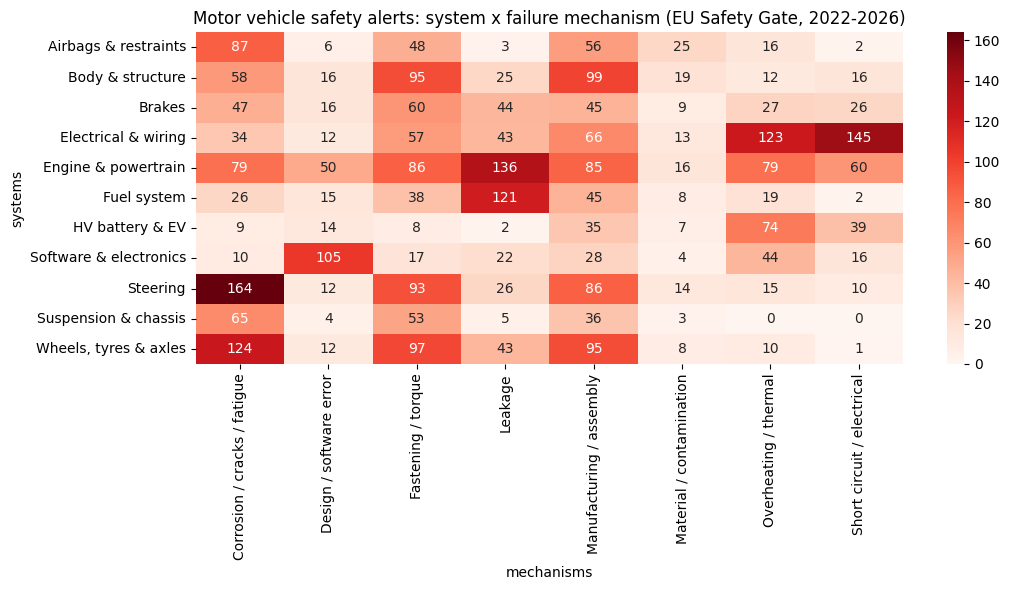

In [7]:
SYSTEMS = {
    'Brakes': r'brak|brake|abs\b|esc\b|caliper|disc',
    'Steering': r'steer|track rod|tie rod|rack',
    'Airbags & restraints': r'airbag|inflator|seat ?belt|seatbelt|restraint|pretensioner',
    'Fuel system': r'fuel|injector|common rail|tank',
    'HV battery & EV': r'high.voltage|hv\b|battery cell|cell module|traction battery|charging|inverter|bms\b',
    'Electrical & wiring': r'wiring|harness|cable|connector|fuse|short circuit|electrical|relay|ground connection|earthing',
    'Engine & powertrain': r'engine|camshaft|crankshaft|transmission|gear|clutch|turbo|oil|coolant|propulsion|drive shaft|output shaft',
    'Wheels, tyres & axles': r'wheel|tyre|tire|rim|axle|tread',
    'Suspension & chassis': r'suspension|strut|shock absorber|subframe|chassis|frame|leaf spring|control arm',
    'Body & structure': r'bonnet|hood|door|seat\b|seats\b|roof|panel|bumper|body|mudguard',
    'Software & electronics': r'software|control unit|calibration|sensor|display|ecu\b|programm',
}
MECHANISMS = {
    'Fastening / torque': r'tighten|torque|loose|loosen|unscrew|nut\b|nuts\b|bolt|screw|fixing|attach',
    'Leakage': r'leak|seep|spill|ingress|infiltrat',
    'Overheating / thermal': r'overheat|heat|thermal|temperature|smoulder|smolder|melt',
    'Short circuit / electrical': r'short.circuit|arc\b|electrical fault|insulation|contact resistance',
    'Corrosion / cracks / fatigue': r'corro|crack|fatigue|fracture|break|rupture|wear|deteriorat|degrad',
    'Manufacturing / assembly': r'manufactur|assembl|install|weld|produc|positioned|fitted|cast',
    'Design / software error': r'software|design|calibrat|programm|configuration',
    'Material / contamination': r'material|asbestos|contamina|particle|residue|substance',
}

def tag(text, dictionary):
    text = text.lower()
    return [label for label, pattern in dictionary.items() if re.search(pattern, text)]

mv['systems'] = mv['danger_clean'].apply(lambda t: tag(t, SYSTEMS))
mv['mechanisms'] = mv['danger_clean'].apply(lambda t: tag(t, MECHANISMS))
print(f"Alerts with a system tag   : {(mv['systems'].str.len() > 0).mean():.1%}")
print(f"Alerts with a mechanism tag: {(mv['mechanisms'].str.len() > 0).mean():.1%}")

long = mv[['caseNumber', 'systems', 'mechanisms']].explode('systems').explode('mechanisms').dropna()
matrix = pd.crosstab(long['systems'], long['mechanisms'])

plt.figure(figsize=(11, 6))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Reds')
plt.title('Motor vehicle safety alerts: system x failure mechanism (EU Safety Gate, 2022-2026)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_system_mechanism_heatmap.png'), dpi=200)
plt.show()

## 7. Temporal distribution and hazard pathways

In [8]:
sys_year = mv[['year', 'systems']].explode('systems').dropna()
print((pd.crosstab(sys_year['year'], sys_year['systems'], normalize='index') * 100).round(1))

mv['fire'] = mv['riskType'].str.contains('Fire', na=False)
mv['injury'] = mv['riskType'].str.contains('Injur', na=False)
mech_risk = mv[['mechanisms', 'fire', 'injury']].explode('mechanisms').dropna()
risk_table = mech_risk.groupby('mechanisms')[['fire', 'injury']].mean().mul(100).round(1)
risk_table['n_alerts'] = mech_risk['mechanisms'].value_counts()
print(risk_table.sort_values('fire', ascending=False))

systems  Airbags & restraints  Body & structure  Brakes  Electrical & wiring  \
year                                                                           
2022                      9.3              12.0     9.7                 11.5   
2023                     11.7              11.9     8.7                  9.1   
2024                     10.8              10.8    10.4                 10.2   
2025                      7.8               9.0    11.7                 10.1   
2026                     10.1              15.0     5.9                 11.6   

systems  Engine & powertrain  Fuel system  HV battery & EV  \
year                                                         
2022                    12.2          5.4              5.4   
2023                    14.6          6.6              4.3   
2024                    16.0          3.9              4.8   
2025                    16.4          6.0              3.9   
2026                    14.6          6.9              6.1   

syst

## 8. Causal knowledge graph and hub root causes

In [9]:
EVENTS = {
    'Loose fastener': r'loose|loosen|unscrew|tighten|torque',
    'Crack / fracture': r'crack|fracture|break|broken|rupture',
    'Corrosion': r'corro',
    'Water ingress': r'water|moisture|humidity',
    'Wiring damage': r'harness|wiring|cable|insulation',
    'Fuel leak': r'fuel.{0,30}leak|leak.{0,30}fuel',
    'Oil / fluid leak': r'oil.{0,30}leak|leak.{0,30}oil|brake fluid|coolant',
    'Short circuit': r'short.circuit|electric arc',
    'Overheating': r'overheat|thermal|temperature|heat',
    'Airbag malfunction': r'airbag|inflator',
    'Fragments projected': r'fragment',
    'Part detachment': r'detach|fall off|come off|separate',
    'Loss of steering': r'steering',
    'Loss of braking': r'brak',
    'Loss of propulsion': r'loss of (drive|power|propulsion)|engine (failure|stall|shut)|stall',
    'Loss of control': r'loss of (vehicle )?control|lose control|stability',
    'Fire': r'fire|burn|smoke|ignite',
    'Accident': r'accident|crash|collision|fall\b',
    'Injury': r'injur',
}

def first_event(text):
    text = str(text).lower()
    for label, pattern in EVENTS.items():
        if re.search(pattern, text):
            return label
    return None

pairs_df['cause_event'] = pairs_df['cause'].apply(first_event)
pairs_df['effect_event'] = pairs_df['effect'].apply(first_event)
edges = (pairs_df.dropna(subset=['cause_event', 'effect_event'])
         .query('cause_event != effect_event')
         .groupby(['cause_event', 'effect_event']).size()
         .reset_index(name='weight').sort_values('weight', ascending=False))
edges.to_csv(os.path.join(DATA_DIR, 'causal_graph_edges.csv'), index=False)
print(edges.head(15).to_string(index=False))

       cause_event    effect_event  weight
       Overheating            Fire      74
   Loss of control        Accident      62
   Loss of braking        Accident      59
Airbag malfunction          Injury      50
  Crack / fracture        Accident      48
          Accident          Injury      45
  Loss of steering        Accident      45
     Short circuit            Fire      41
   Part detachment        Accident      35
    Loose fastener        Accident      32
         Fuel leak            Fire      31
Loss of propulsion        Accident      28
     Short circuit     Overheating      27
  Crack / fracture Loss of control      19
    Loose fastener Part detachment      18


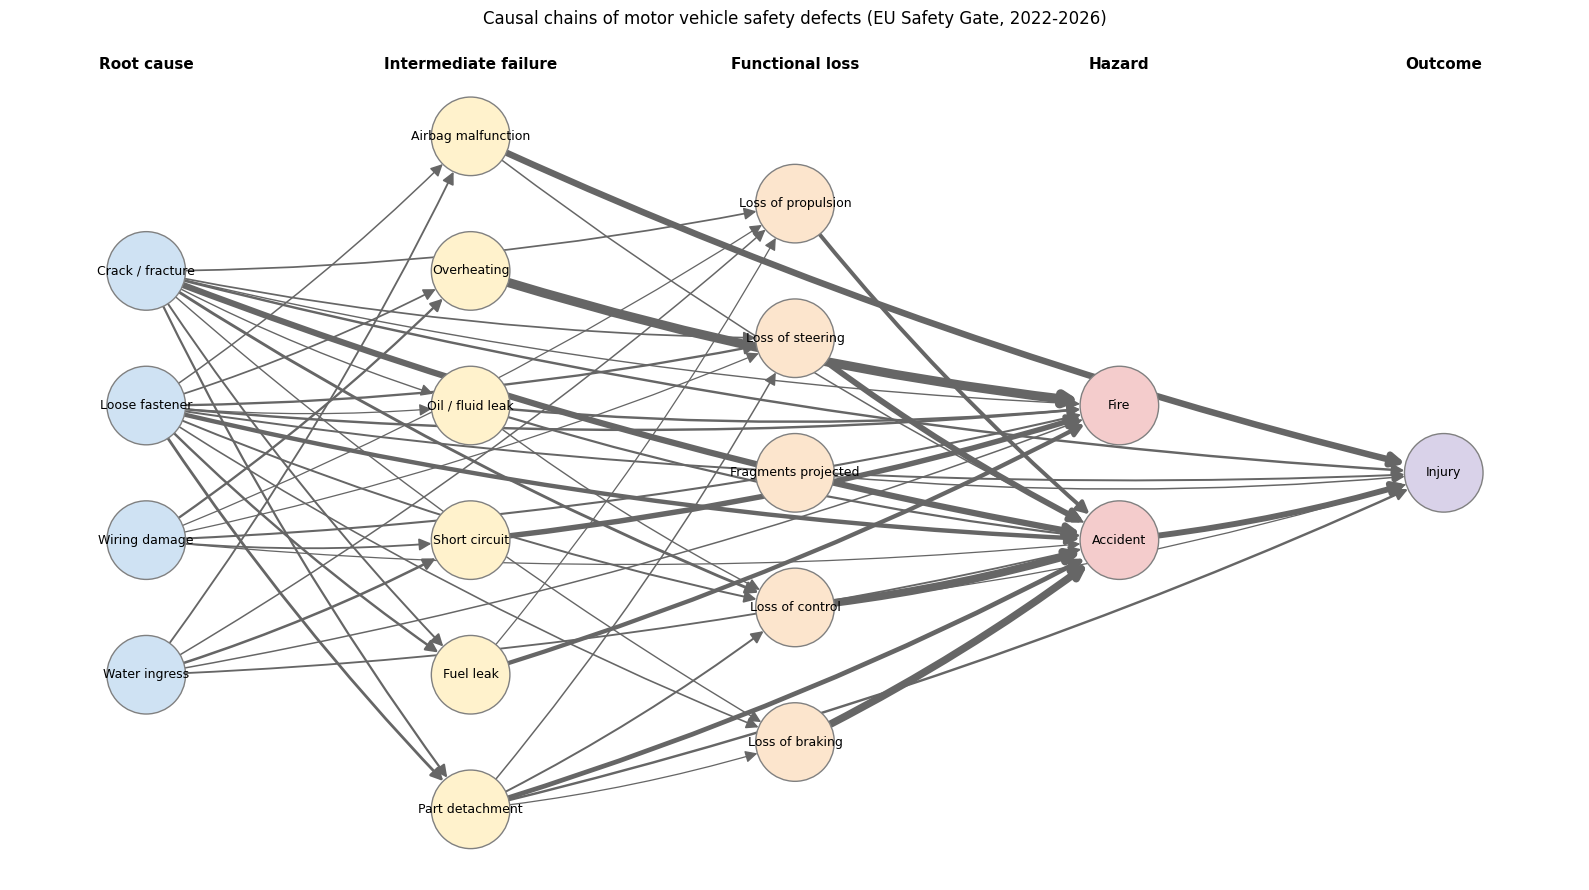

In [10]:
LEVELS = {
    'Loose fastener': 0, 'Crack / fracture': 0, 'Corrosion': 0, 'Water ingress': 0, 'Wiring damage': 0,
    'Fuel leak': 1, 'Oil / fluid leak': 1, 'Short circuit': 1, 'Overheating': 1,
    'Airbag malfunction': 1, 'Part detachment': 1,
    'Loss of steering': 2, 'Loss of braking': 2, 'Loss of propulsion': 2,
    'Loss of control': 2, 'Fragments projected': 2,
    'Fire': 3, 'Accident': 3, 'Injury': 4,
}
LEVEL_NAMES = ['Root cause', 'Intermediate failure', 'Functional loss', 'Hazard', 'Outcome']
COLORS = ['#cfe2f3', '#fff2cc', '#fce5cd', '#f4cccc', '#d9d2e9']

fwd = edges[edges.apply(lambda e: LEVELS.get(e['cause_event'], -1) < LEVELS.get(e['effect_event'], -1), axis=1)]
fwd = fwd[fwd['weight'] >= 5]

G = nx.DiGraph()
for node, lvl in LEVELS.items():
    G.add_node(node, layer=lvl)
for _, e in fwd.iterrows():
    G.add_edge(e['cause_event'], e['effect_event'], weight=e['weight'])
G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])
pos = nx.multipartite_layout(G, subset_key='layer', align='vertical', scale=2)

plt.figure(figsize=(16, 9))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=[COLORS[G.nodes[n]['layer']] for n in G.nodes], edgecolors='gray')
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, width=[0.5 + G[u][v]['weight'] / 12 for u, v in G.edges()],
                       arrows=True, arrowstyle='-|>', arrowsize=18, edge_color='#666666',
                       node_size=3200, connectionstyle='arc3,rad=0.05')
for lvl, name in enumerate(LEVEL_NAMES):
    xs = [pos[n][0] for n in G.nodes if G.nodes[n]['layer'] == lvl]
    if xs:
        plt.text(sum(xs) / len(xs), 2.35, name, ha='center', fontsize=11, fontweight='bold')
plt.title('Causal chains of motor vehicle safety defects (EU Safety Gate, 2022-2026)', pad=30)
plt.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_causal_chains_layered.png'), dpi=200, bbox_inches='tight')
plt.show()

In [11]:
thermal = {'Fire', 'Overheating', 'Short circuit', 'Fuel leak', 'Oil / fluid leak'}
mechanical = {'Accident', 'Loss of control', 'Loss of steering', 'Loss of braking',
              'Part detachment', 'Injury', 'Loss of propulsion'}
root_causes = [n for n, l in LEVELS.items() if l <= 1]

hub = (edges[edges['cause_event'].isin(root_causes)]
       .groupby('cause_event')
       .agg(distinct_effects=('effect_event', 'nunique'), total_links=('weight', 'sum')))
link_sum = lambda c, targets: edges[(edges['cause_event'] == c) & edges['effect_event'].isin(targets)]['weight'].sum()
hub['thermal_links'] = [link_sum(c, thermal) for c in hub.index]
hub['mechanical_links'] = [link_sum(c, mechanical) for c in hub.index]
hub['thermal_share'] = (hub['thermal_links'] / (hub['thermal_links'] + hub['mechanical_links'])).round(2)
hub = hub.sort_values('distinct_effects', ascending=False)
hub.to_csv(os.path.join(DATA_DIR, 'hub_root_causes.csv'))
hub

,distinct_effects,total_links,thermal_links,mechanical_links,thermal_share
cause_event,,,,,
Loose fastener,15,161,46,95,0.33
Crack / fracture,14,150,24,119,0.17
Wiring damage,13,61,38,18,0.68
Overheating,11,100,79,10,0.89
Corrosion,10,32,5,10,0.33
Water ingress,10,65,25,20,0.56
Part detachment,10,85,10,75,0.12
Oil / fluid leak,9,64,30,32,0.48
Short circuit,8,79,68,9,0.88


## 9. Summary of findings
* **Extraction quality:** rule-based extraction covers ~84% of alerts; manual validation on 100 random pairs gives 93% cause, 95% effect and 91% pair accuracy.
* **Two hazard pathways:** thermal mechanisms (short circuits, overheating, leakage) lead predominantly to fire, whereas structural mechanisms (cracks/fatigue, loose fasteners, assembly errors) lead predominantly to injury.
* **Hub root cause:** loose fasteners / torque errors connect to the largest number of distinct effects and feed both the thermal and the mechanical pathway.
* **Stable distribution:** the share of vehicle systems among alerts is broadly stable across 2022–2026.

## 10. Limitations and future work
* Pronoun resolution, parallel causes and sentence boundary errors in the rule-based extractor
* Keyword dictionaries partially overlap between system and mechanism tags (e.g., "software", "short circuit")
* Alert texts compress causal chains, so intermediate steps are often missing
* Future work: supervised causal sentence classification, transformer-based span extraction, and ontology-based normalisation of causal events